In [1]:
from pathlib import Path
import math

import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits

In [2]:
# The only required input.
cube_dir = Path("cubes/N64_L16")

In [3]:
if not cube_dir.is_dir():
    raise FileNotFoundError(f"Folder not found: {cube_dir.resolve()}")

all_paths = sorted(
    path for path in cube_dir.iterdir()
    if path.is_file() and path.suffix.lower() == ".fits"
)

if not all_paths:
    raise FileNotFoundError(f"No FITS files found in {cube_dir.resolve()}")

catalog = {}

for path in all_paths:
    header = fits.getheader(path)

    if header.get("NAXIS") != 3:
        print(f"Skipping non-3D primary HDU: {path.name}")
        continue

    catalog[path.name] = {
        "path": path,
        "header": header,
        "shape": (
            header["NAXIS3"],
            header["NAXIS2"],
            header["NAXIS1"],
        ),
    }

if not catalog:
    raise ValueError("No 3D cubes found.")

print(f"Loaded metadata for {len(catalog)} cubes.")

Loaded metadata for 10 cubes.


In [4]:
for index, (name, entry) in enumerate(catalog.items(), start=1):
    h = entry["header"]

    std = float(h.get("STD", np.nan))
    lengths = tuple(h.get(f"LSCALE_{axis}", np.nan) for axis in "XYZ")

    print(
        f"[{index}] {name}\n"
        f"    Model: {h.get('MODEL', '?')} | "
        f"Field: {h.get('FIELD', '?')} | "
        f"M3D: {h.get('M3D', '?')} | "
        f"Seed: {h.get('SEED', '?')}\n"
        f"    Shape: {entry['shape']} | "
        f"Length scales: {lengths}\n"
        f"    Mean: {float(h.get('MEAN', np.nan)):.6f} | "
        f"Std: {std:.6f} | "
        f"Variance: {std**2:.6f}\n"
    )



[1] exponential_3d_density_N64_L16.fits
    Model: exponential | Field: density | M3D: 1.0 | Seed: 19970221
    Shape: (64, 64, 64) | Length scales: (16.0, 16.0, 16.0)
    Mean: 0.119037 | Std: 0.808663 | Variance: 0.653936

[2] exponential_3d_velocity_N64_L16.fits
    Model: exponential | Field: velocity | M3D: 1.0 | Seed: 19880127
    Shape: (64, 64, 64) | Length scales: (16.0, 16.0, 16.0)
    Mean: -0.362553 | Std: 0.797601 | Variance: 0.636168

[3] gaussian_3d_density_N64_L16.fits
    Model: gaussian | Field: density | M3D: 2.0 | Seed: 19970221
    Shape: (64, 64, 64) | Length scales: (16.0, 16.0, 16.0)
    Mean: -0.237722 | Std: 0.861882 | Variance: 0.742840

[4] gaussian_3d_velocity_N64_L16.fits
    Model: gaussian | Field: velocity | M3D: 2.0 | Seed: 19880127
    Shape: (64, 64, 64) | Length scales: (16.0, 16.0, 16.0)
    Mean: -0.165863 | Std: 0.945215 | Variance: 0.893432

[5] stable_alpha1.5_3d_density_N64_L16.fits
    Model: stable | Field: density | M3D: 1.5 | Seed: 1997022

In [5]:
summary_blocks = []

for index, (name, entry) in enumerate(catalog.items(), start=1):
    h = entry["header"]

    std = float(h.get("STD", np.nan))
    lengths = tuple(
        h.get(f"LSCALE_{axis}", np.nan)
        for axis in "XYZ"
    )

    block = (
        f"[{index}] {name}\n"
        f"    Model: {h.get('MODEL', '?')} | "
        f"Field: {h.get('FIELD', '?')} | "
        f"M3D: {h.get('M3D', '?')} | "
        f"Seed: {h.get('SEED', '?')}\n"
        f"    Shape: {entry['shape']} | "
        f"Length scales: {lengths}\n"
        f"    Mean: {float(h.get('MEAN', np.nan)):.6f} | "
        f"Std: {std:.6f} | "
        f"Variance: {std**2:.6f}"
    )

    summary_blocks.append(block)

summary_text = "\n\n".join(summary_blocks) + "\n"

print(summary_text)

summary_path = cube_dir / f"summary_{cube_dir.name}.txt"
summary_path.write_text(summary_text, encoding="utf-8")

print(f"Saved: {summary_path}")


[1] exponential_3d_density_N64_L16.fits
    Model: exponential | Field: density | M3D: 1.0 | Seed: 19970221
    Shape: (64, 64, 64) | Length scales: (16.0, 16.0, 16.0)
    Mean: 0.119037 | Std: 0.808663 | Variance: 0.653936

[2] exponential_3d_velocity_N64_L16.fits
    Model: exponential | Field: velocity | M3D: 1.0 | Seed: 19880127
    Shape: (64, 64, 64) | Length scales: (16.0, 16.0, 16.0)
    Mean: -0.362553 | Std: 0.797601 | Variance: 0.636168

[3] gaussian_3d_density_N64_L16.fits
    Model: gaussian | Field: density | M3D: 2.0 | Seed: 19970221
    Shape: (64, 64, 64) | Length scales: (16.0, 16.0, 16.0)
    Mean: -0.237722 | Std: 0.861882 | Variance: 0.742840

[4] gaussian_3d_velocity_N64_L16.fits
    Model: gaussian | Field: velocity | M3D: 2.0 | Seed: 19880127
    Shape: (64, 64, 64) | Length scales: (16.0, 16.0, 16.0)
    Mean: -0.165863 | Std: 0.945215 | Variance: 0.893432

[5] stable_alpha1.5_3d_density_N64_L16.fits
    Model: stable | Field: density | M3D: 1.5 | Seed: 1997022

Saved: cubes/N64_L16/central_slices_N64_L16.png


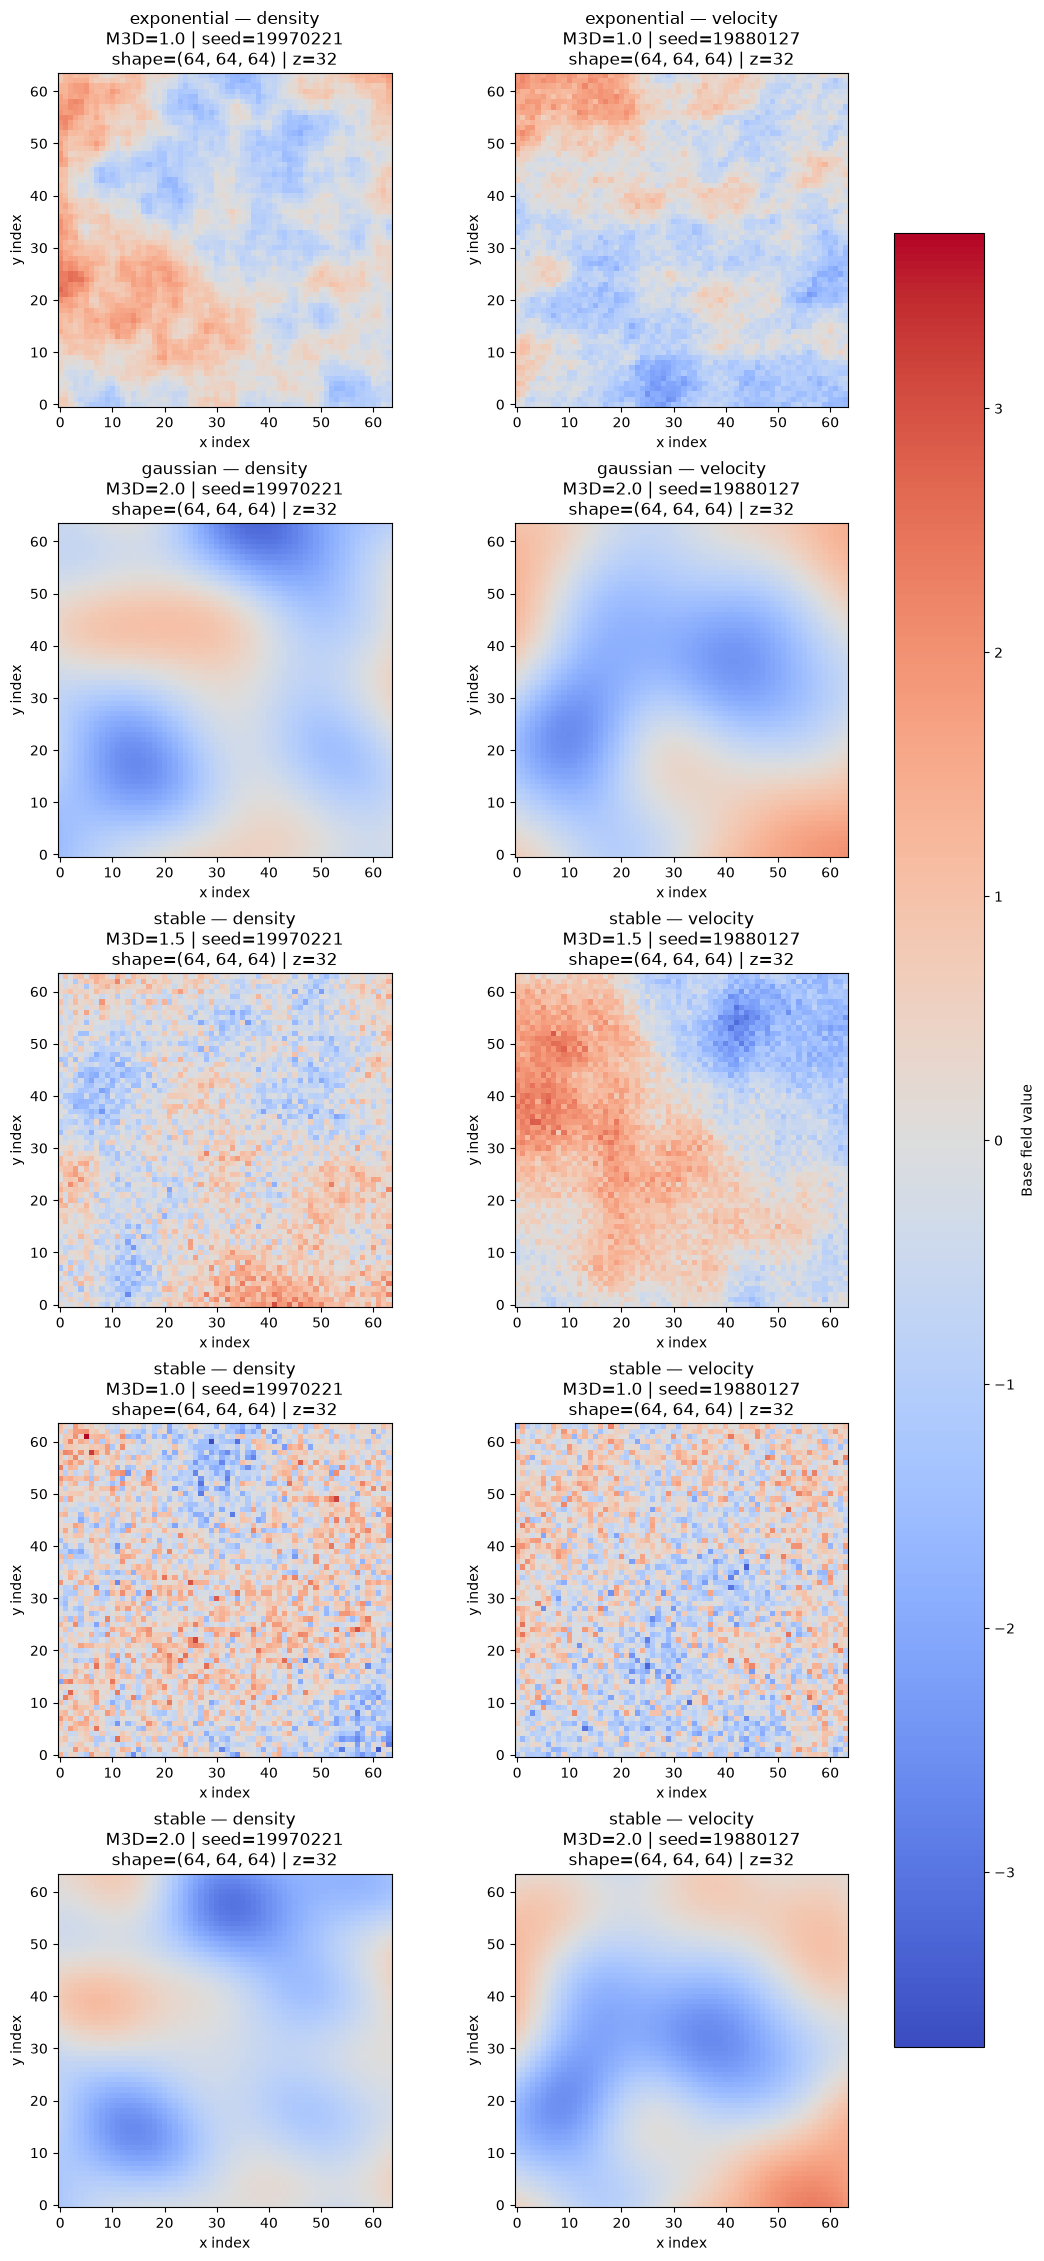

In [6]:

slices = {}

for name, entry in catalog.items():
    with fits.open(entry["path"]) as hdul:
        cube = hdul[0].data
        iz = cube.shape[2] // 2

        slices[name] = {
            "image": np.array(cube[:, :, iz], dtype=float),
            "iz": iz,
        }

# Common symmetric limits, ignoring nonfinite values.
vlim = 0.0

for entry in slices.values():
    image = entry["image"]
    finite = np.isfinite(image)

    if finite.any():
        vlim = max(vlim, float(np.abs(image[finite]).max()))

if vlim == 0:
    vlim = 1.0

ncols = min(2, len(slices))
nrows = math.ceil(len(slices) / ncols)

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(5.5 * ncols, 4.5 * nrows),
    squeeze=False,
    constrained_layout=True,
)

used_axes = []

for ax, (name, entry) in zip(axes.flat, slices.items()):
    h = catalog[name]["header"]

    im = ax.imshow(
        np.ma.masked_invalid(entry["image"].T),
        origin="lower",
        cmap="coolwarm",
        vmin=-vlim,
        vmax=vlim,
        interpolation="nearest",
    )

    ax.set_title(
        f"{h.get('MODEL', '?')} — {h.get('FIELD', '?')}\n"
        f"M3D={h.get('M3D', '?')} | "
        f"seed={h.get('SEED', '?')}\n"
        f"shape={catalog[name]['shape']} | z={entry['iz']}"
    )
    ax.set_xlabel("x index")
    ax.set_ylabel("y index")
    used_axes.append(ax)

for ax in list(axes.flat)[len(slices):]:
    ax.set_visible(False)

fig.colorbar(
    im,
    ax=used_axes,
    label="Base field value",
    shrink=0.85,
)

figure_path = cube_dir / f"central_slices_{cube_dir.name}.png"

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)

print(f"Saved: {figure_path}")

plt.show()

In [7]:
list(catalog)  # Available filenames

['exponential_3d_density_N64_L16.fits',
 'exponential_3d_velocity_N64_L16.fits',
 'gaussian_3d_density_N64_L16.fits',
 'gaussian_3d_velocity_N64_L16.fits',
 'stable_alpha1.5_3d_density_N64_L16.fits',
 'stable_alpha1.5_3d_velocity_N64_L16.fits',
 'stable_alpha1_3d_density_N64_L16.fits',
 'stable_alpha1_3d_velocity_N64_L16.fits',
 'stable_alpha2_3d_density_N64_L16.fits',
 'stable_alpha2_3d_velocity_N64_L16.fits']

In [8]:
#header = catalog["exponential_3d_density_N128_L16.fits"]["header"]
#print(header)

In [9]:
from pathlib import Path

print("Working directory:", Path.cwd())

cubes_root = Path("cubes")

if cubes_root.is_dir():
    print("\nAvailable folders:")
    for folder in sorted(cubes_root.iterdir()):
        if folder.is_dir():
            print(folder)
else:
    print("\nNo 'cubes' folder found here.")

Working directory: /Users/javier/fake_maps_gs/creating_cubes_V0.1

Available folders:
cubes/N128_L16
cubes/N256_L16
cubes/N64_L16
cubes/batch_test_64
